# [14.7] Recurrent World Models - Dreamer, TD-MPC2 and IRIS (solutions)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter14_jepa_world_models/exercises/part7_recurrent_world_models/14.7_Recurrent_World_Models_Dreamer_TD-MPC2_and_IRIS_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter14_jepa_world_models/exercises/part7_recurrent_world_models/14.7_Recurrent_World_Models_Dreamer_TD-MPC2_and_IRIS_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

A five-room corridor has a reward in room 4. The agent starts in room 0 and can move left, stay or move right. A model says “keep walking into the left wall: it pays ten every step.” **Does optimizing that imagined reward improve behavior in the real corridor?**

By the end of this notebook, you will have shown that a planner can exploit a reward-model error despite accurate transition predictions, using a controlled corridor and an explicit imagined-versus-real return figure. You will also build the actual mathematical cores that distinguish three families: a recurrent stochastic state-space model (RSSM), a decoder-free latent consistency/value objective, and a discrete-token causal transformer world model.

These are **three separately trained tiny organisms**, not one generic transition table under three model names. We keep their state, objective and training code visible. A fixed CPU recipe fits small modules on public corridor transitions; it does not reproduce Dreamer, TD-MPC2 or IRIS benchmark agents. Actor learning, full image tokenization, native simulator performance and robotics safety remain distinct pending work. We will state every approximation at the point it enters.

Prerequisites: transformer attention (1.1), categorical distributions and autograd, temporal-difference targets, 14.3 planning. No external environment, checkpoint, GPU or network is needed.

## Content & Learning Objectives

### 1️⃣ Remember and imagine with an RSSM

> ##### Learning Objectives
>
> - Implement recurrent deterministic state, categorical prior/posterior, balanced KL and lambda returns.

### 2️⃣ Train a decoder-free latent objective

> ##### Learning Objectives
>
> - Implement SimNorm, consistency/reward/TD losses and finite-horizon action planning.

### 3️⃣ Tokenize observations and predict causally

> ##### Learning Objectives
>
> - Implement codebook quantization, VQ gradients and a causal transformer next-state-token model.

### 4️⃣ When imagined reward is exploited

> ##### Learning Objectives
>
> - Compare imagined rollouts to the real chain and expose a deliberately corrupted reward model.

## Setup code

This study edition uses tiny CPU fixtures: no network, pretrained checkpoint, GPU or additional installation.

In [1]:
from pathlib import Path
import sys
import itertools
import numpy as np
import torch as t
import torch.nn.functional as F
import matplotlib.pyplot as plt
chapter = "chapter14_jepa_world_models"
section = "part7_recurrent_world_models"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part7_recurrent_world_models.tests as tests
MAIN = __name__ == "__main__"
device = t.device("cpu")
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ Remember and imagine with an RSSM

> ##### Learning Objectives
>
> - Implement recurrent deterministic state, categorical prior/posterior, balanced KL and lambda returns.

Rooms are integers `0..4`; actions are `0=left, 1=stay, 2=right`. The next room clips at the walls, and reward is one when the **next** room is 4. The episode does not terminate, so staying at room 4 yields continuing reward.

An RSSM combines a deterministic memory $h_t$ and a categorical latent $z_t$. We use
$$h_t=\mathrm{GRU}([z_{t-1},\mathrm{onehot}(a_{t-1})],h_{t-1}),\quad p(z_t|h_t),\quad q(z_t|h_t,o_t).$$
The prior imagines without the current observation; the posterior sees it. Reconstruction and reward heads read `[h,z]`. The initial observed room one-hot seeds `z0` directly; later posterior codes are learned. Here one categorical variable has five classes; released Dreamer uses richer latent groups and additional training machinery. Sampling uses a straight-through categorical estimator: forward values are one-hot while gradients follow probabilities. This is an estimator, not a differentiable categorical draw.

### Exercise - implement `chain_step`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement the complete corridor transition and reward for scalar or batched integer inputs. Reward belongs to the destination. The same environment will evaluate all model rollouts and selected plans.

In [2]:
def chain_step(state, action):
    next_state=np.clip(np.asarray(state)+np.asarray(action)-1,0,4).astype(int)
    return next_state,(next_state==4).astype(float)


tests.test_chain_step(chain_step)

All tests in test_chain_step passed!


<details><summary>Hint</summary>

Action labels are offsets shifted upward by one.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_chain_step passed!`. Walking right from room3 enters room4 and earns1; walking left into room0 stays0 and earns0.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `straight_through_state`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return one-hot categorical states with a straight-through probability gradient. Sampling uses the current Torch RNG; mode evaluation uses the earliest maximum. Keep the batch dimensions. We sample during fitting and use mode rollouts for the displayed deterministic comparison.

In [3]:
def straight_through_state(logits, sample=True):
    probs=logits.softmax(dim=-1)
    if sample:
        index=t.multinomial(probs.reshape(-1,probs.shape[-1]),1).reshape(probs.shape[:-1])
    else:
        index=probs.argmax(dim=-1)
    hard=F.one_hot(index,probs.shape[-1]).to(probs.dtype)
    return probs+(hard-probs).detach()


tests.test_straight_through_state(straight_through_state)

All tests in test_straight_through_state passed!


<details><summary>Hint</summary>

Use `probabilities + (hard - probabilities).detach()`; detaching the whole result kills the estimator.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_straight_through_state passed!`. The forward state is class1; its gradient is the softmax weighted-value derivative.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `categorical_kl`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute per-example KL `KL(q||p)` in nats without reducing the batch. Use log-softmax for numerical stability. Reversing the KL arguments changes which distribution is penalized; our independent fixture is asymmetric.

In [4]:
def categorical_kl(posterior_logits, prior_logits):
    logq=posterior_logits.log_softmax(dim=-1)
    logp=prior_logits.log_softmax(dim=-1)
    return (logq.exp()*(logq-logp)).sum(dim=-1)


tests.test_categorical_kl(categorical_kl)

All tests in test_categorical_kl passed!


<details><summary>Hint</summary>

The weighting distribution is the posterior q.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_categorical_kl passed!`. The asymmetric fixture KL is approximately `.130812` nats.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `rssm_transition`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Perform one recurrent transition. The posterior may access only the supplied current observation. Passing `None` must use the prior and return `posterior=None`. Shapes are `h=(batch,8)`, `z=(batch,5)`, action `(batch,)`, observation `(batch,5)` in our instantiated model.

In [5]:
def rssm_transition(model, h, z, action, observation=None, sample=True):
    a=F.one_hot(action.long(),3).to(h.dtype)
    h=model["memory"](t.cat([z,a],dim=-1),h)
    prior=model["prior"](h)
    posterior=None if observation is None else model["posterior"](t.cat([h,observation],dim=-1))
    new_z=straight_through_state(prior if posterior is None else posterior,sample=sample)
    return h,new_z,prior,posterior


tests.test_rssm_transition(rssm_transition)

All tests in test_rssm_transition passed!


<details><summary>Hint</summary>

Compute h before both distributions; select posterior only when an observation exists.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_rssm_transition passed!`. The fixture posterior and prior select different states, proving observations are absent during imagination.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `balanced_kl`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement separate dynamics and representation KL terms with stop-gradients on opposite sides. Clamp each per-example KL before averaging. Our one-categorical teaching model uses `.1` free nats; that is not an assertion of released Dreamer hyperparameters. Dynamics loss trains the prior; representation loss trains the posterior.

In [6]:
def balanced_kl(posterior, prior, free_nats=0.1):
    dynamics=categorical_kl(posterior.detach(),prior).clamp_min(free_nats).mean()
    representation=categorical_kl(posterior,prior.detach()).clamp_min(free_nats).mean()
    return .5*dynamics+.1*representation


tests.test_balanced_kl(balanced_kl)

All tests in test_balanced_kl passed!


<details><summary>Hint</summary>

Free nats create a floor on the loss and zero KL gradient below the floor.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_balanced_kl passed!`. Equal distributions with free nats .2 give total KL term .12 and no KL gradient.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `lambda_returns`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute finite imagined lambda returns, using `values` of length `len(rewards)+1`. The last value bootstraps the final step. We implement the return target to expose the behavior-learning bridge; we do not train Dreamer’s actor/critic in this notebook.

In [7]:
def lambda_returns(rewards, values, gamma=0.95, lam=0.8):
    out=np.empty_like(rewards,dtype=float)
    carry=float(values[-1])
    for i in range(len(rewards)-1,-1,-1):
        carry=float(rewards[i])+gamma*((1-lam)*float(values[i+1])+lam*carry)
        out[i]=carry
    return out


tests.test_lambda_returns(lambda_returns)

All tests in test_lambda_returns passed!


<details><summary>Hint</summary>

Iterate backwards; at lambda0 use the one-step value, at lambda1 use the full recursive return.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_lambda_returns passed!`. The two-step fixture gives `[2.5,4]` at λ0 and `[3,4]` at λ1.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

In [8]:
def make_rssm():
    return t.nn.ModuleDict({"memory":t.nn.GRUCell(8,8),"prior":t.nn.Linear(8,5),"posterior":t.nn.Linear(13,5),"decode":t.nn.Linear(13,5),"reward":t.nn.Linear(13,1)})

previous_threads=t.get_num_threads();t.set_num_threads(1);t.manual_seed(43)
# Every initial room paired with all 27 action sequences of length three.
action_sequences=np.array(list(itertools.product(range(3),repeat=3)))
actions_np=np.tile(action_sequences,(5,1));starts=np.repeat(np.arange(5),len(action_sequences))
room_trace=[starts]
for i in range(3):room_trace.append(chain_step(room_trace[-1],actions_np[:,i])[0])
room_trace=np.stack(room_trace,axis=1)
obs=F.one_hot(t.tensor(room_trace),5).float();acts=t.tensor(actions_np)
rssm=make_rssm();optimizer=t.optim.Adam(rssm.parameters(),lr=.025);rssm_losses=[]
for update in range(80):
    h=t.zeros(len(starts),8);z=obs[:,0];loss=t.tensor(0.)
    for i in range(3):
        h,z,prior,posterior=rssm_transition(rssm,h,z,acts[:,i],obs[:,i+1],sample=True)
        state=t.cat([h,z],-1)
        reconstruction=F.cross_entropy(rssm["decode"](state),t.tensor(room_trace[:,i+1]))
        reward_target=(obs[:,i+1,4]).unsqueeze(-1)
        loss=loss+reconstruction+F.mse_loss(rssm["reward"](state),reward_target)+balanced_kl(posterior,prior)
    optimizer.zero_grad();loss.backward();optimizer.step();rssm_losses.append(float(loss.detach()/3))
print("RSSM mean step loss initial/final:",round(rssm_losses[0],5),round(rssm_losses[-1],5))

RSSM mean step loss initial/final: 1.94985 0.14671


## Probe the frozen recurrent state

A reconstruction decoder was trained jointly with the RSSM. To ask a different question, freeze the model and fit a fresh **linear state probe** to `[h,z]` features. We collect observation-conditioned posterior states from the public three-step corpus; fit on alternating feature rows and check on the other rows. This is decodability on public traces, not unseen environment evaluation. A shuffled fitting-label control catches easy memorization or class imbalance. An accurate probe does not show that the planner uses the decoded room; the reward-error experiment later tests behavior separately.

### Exercise - implement `linear_room_probe`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Fit an affine least-squares classifier to room indicators and return all predicted room labels plus accuracy on the complementary check rows. Fit only the specified rows. Ties choose the earliest room. Do not fit the reconstruction decoder or modify the RSSM.

In [9]:
def linear_room_probe(features, room_labels, fitting_mask):
    labels=np.asarray(room_labels,dtype=int)
    fit=np.asarray(fitting_mask,dtype=bool)
    design=np.c_[features,np.ones(len(features))]
    target=np.eye(5)[labels]
    weights=np.linalg.lstsq(design[fit],target[fit],rcond=None)[0]
    prediction=(design@weights).argmax(axis=-1)
    accuracy=float(np.mean(prediction[~fit]==labels[~fit]))
    return prediction,accuracy


tests.test_linear_room_probe(linear_room_probe)

All tests in test_linear_room_probe passed!


<details><summary>Hint</summary>

Append an intercept, regress one-hot labels only on fitting rows, then classify by the largest output.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_linear_room_probe passed!`. The identity-room fixture checks at accuracy1; a cyclic fitting-label mismatch gives0.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

frozen posterior-state probe / shuffled-label control: 1.0 0.1188


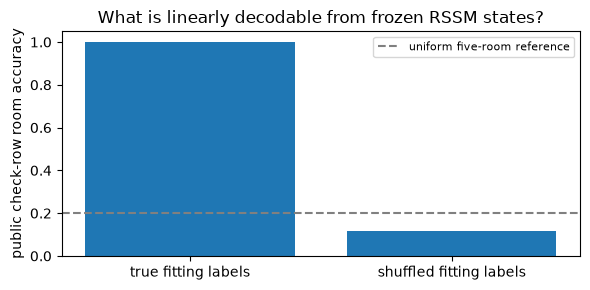

In [10]:
probe_features=[];probe_labels=[]
h=t.zeros(len(starts),8);z=obs[:,0]
with t.no_grad():
    for i in range(3):
        h,z,_,_=rssm_transition(rssm,h,z,acts[:,i],obs[:,i+1],sample=False)
        probe_features.append(t.cat([h,z],-1).numpy());probe_labels.append(room_trace[:,i+1])
probe_features=np.concatenate(probe_features);probe_labels=np.concatenate(probe_labels)
probe_fit=np.arange(len(probe_labels))%2==0
_,probe_accuracy=linear_room_probe(probe_features,probe_labels,probe_fit)
shuffled_probe_labels=probe_labels.copy()
shuffled_probe_labels[probe_fit]=np.random.default_rng(49).permutation(shuffled_probe_labels[probe_fit])
_,probe_control=linear_room_probe(probe_features,shuffled_probe_labels,probe_fit)
print("frozen posterior-state probe / shuffled-label control:",round(probe_accuracy,4),round(probe_control,4))
fig,ax=plt.subplots(figsize=(6,3))
ax.bar(["true fitting labels","shuffled fitting labels"],[probe_accuracy,probe_control])
ax.axhline(.2,color="grey",ls="--",label="uniform five-room reference")
ax.set(ylim=(0,1.05),ylabel="public check-row room accuracy",title="What is linearly decodable from frozen RSSM states?");ax.legend(fontsize=8)
fig.tight_layout();plt.show()

## Summary of 1️⃣

The RSSM learns observation reconstruction, reward and a prior compatible with observation-conditioned posterior states. Posterior reconstruction can be excellent while prior rollouts diverge. Lambda returns expose the next behavior-learning step, which remains untrained here.

# 2️⃣ Train a decoder-free latent objective

> ##### Learning Objectives
>
> - Implement SimNorm, consistency/reward/TD losses and finite-horizon action planning.

A decoder-free latent model does not need to reconstruct observations. Our TD-MPC2-inspired organism has encoder $z=\mathrm{SimNorm}(e(o))$, latent dynamics $d(z,a)$, reward head $r(z,a)$ and scalar Q head $Q(z,a)$. SimNorm partitions a feature vector into groups and softmax-normalizes each group. We use one group of five; the released method uses its configured group structure and more machinery.

For one transition our teaching objective is
$$L=\|d(z,a)-\mathrm{sg}[z']\|_2^2+(\hat r-r)^2+(Q(z,a)-\mathrm{sg}[r+\gamma\max_{a'}Q_{\rm target}(z',a')])^2.$$
This implements latent consistency, reward fitting and temporal-difference learning, but uses MSE scalar heads and a discrete-action max. Released TD-MPC2 uses richer reward/value parameterizations, ensembles, policy priors and continuous-action trajectory optimization. We do not quietly replace those claims with this finite chain. The encoder below is fixed, making the latent space auditable.

### Exercise - implement `simnorm`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Normalize each contiguous group separately. Preserve all outer dimensions. A global softmax across multiple groups would constrain the wrong total mass and fails the independent test.

In [11]:
def simnorm(x, group_size=5):
    if x.shape[-1] % group_size:
        raise ValueError("feature size must divide into equal simplex groups")
    shape=x.shape
    return x.reshape(*shape[:-1],-1,group_size).softmax(dim=-1).reshape(shape)


tests.test_simnorm(simnorm)

All tests in test_simnorm passed!


<details><summary>Hint</summary>

Reshape the feature axis into `(groups,group_size)` before softmax.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_simnorm passed!`. Two groups of two each sum to one, so all four outputs are .5, not .25.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `td_world_loss`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement all three losses and the target detachment. `next_q` is an already selected target value, not a trainable max inside this function. Do not detach reward predictions or the current Q: they must learn.

In [12]:
def td_world_loss(predicted_z, target_z, predicted_reward, reward, q, next_q, gamma=0.95):
    consistency=F.mse_loss(predicted_z,target_z.detach())
    reward_loss=F.mse_loss(predicted_reward,reward)
    target=reward+gamma*next_q.detach()
    value_loss=F.mse_loss(q,target)
    return consistency+reward_loss+value_loss


tests.test_td_world_loss(td_world_loss)

All tests in test_td_world_loss passed!


<details><summary>Hint</summary>

MSE averages each tensor; add the three scalar means.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_td_world_loss passed!`. Consistency1 + reward1 + value1 gives loss3, with no gradients to target state or next Q.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

In [13]:
def td_latent(room):
    return simnorm(4*F.one_hot(room.long(),5).float())

def make_td():
    def head(out):return t.nn.Sequential(t.nn.Linear(8,24),t.nn.Tanh(),t.nn.Linear(24,out))
    return t.nn.ModuleDict({"dynamics":head(5),"reward":head(1),"q":head(1)})

def td_components(model,z,a):
    inputs=t.cat([z,F.one_hot(a.long(),3).float()],-1)
    return simnorm(model["dynamics"](inputs)),model["reward"](inputs).squeeze(-1),model["q"](inputs).squeeze(-1)

t.manual_seed(44)
states=t.arange(5).repeat_interleave(3);actions=t.arange(3).repeat(5)
ns,reward_np=chain_step(states.numpy(),actions.numpy());next_states=t.tensor(ns);rewards=t.tensor(reward_np,dtype=t.float32)
z,z_next=td_latent(states),td_latent(next_states)
td=make_td();target_td=make_td();target_td.load_state_dict(td.state_dict())
optimizer=t.optim.Adam(td.parameters(),lr=.02);td_losses=[]
for update in range(120):
    predicted_z,predicted_r,q=td_components(td,z,actions)
    with t.no_grad():
        next_values=t.stack([td_components(target_td,z_next,t.full_like(actions,a))[2] for a in range(3)],-1).max(-1).values
    loss=td_world_loss(predicted_z,z_next,predicted_r,rewards,q,next_values)
    optimizer.zero_grad();loss.backward();optimizer.step();td_losses.append(float(loss.detach()))
    with t.no_grad():
        for target,source in zip(target_td.parameters(),td.parameters(),strict=True):target.lerp_(source,.05)
print("TD objective initial/final:",round(td_losses[0],5),round(td_losses[-1],5))

TD objective initial/final: 0.77885 0.00053


### Exercise - implement `plan_latent_actions`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Enumerate all `3**horizon` action sequences and score learned latent rollouts with discounted reward plus terminal Q. The planning algorithm sees the learned model only. An optional bonus deliberately corrupts its reward; leave transitions and the real environment unchanged. Enumeration is a finite planner oracle, not the continuous trajectory optimizer of released TD-MPC2.

In [14]:
def plan_latent_actions(model, initial_room, horizon=5, gamma=.95, reward_bonus=None):
    sequences=np.array(list(itertools.product(range(3),repeat=horizon)))
    actions=t.tensor(sequences,dtype=t.long)
    z=td_latent(t.full((len(sequences),),initial_room,dtype=t.long))
    returns=t.zeros(len(sequences));trace=[z.argmax(-1).numpy()]
    with t.no_grad():
        for i in range(horizon):
            next_z,reward,_=td_components(model,z,actions[:,i])
            if reward_bonus is not None:
                reward=reward+reward_bonus(z,actions[:,i])
            returns=returns+gamma**i*reward
            z=next_z;trace.append(z.argmax(-1).numpy())
        terminal=t.stack([td_components(model,z,t.full((len(sequences),),a,dtype=t.long))[2] for a in range(3)],-1).max(-1).values
        returns=returns+gamma**horizon*terminal
    best=int(returns.argmax())
    return sequences[best],float(returns[best]),np.stack(trace,axis=1)[best]


tests.test_plan_latent_actions(plan_latent_actions)

All tests in test_plan_latent_actions passed!


<details><summary>Hint</summary>

Track one discounted scalar per sequence and append the terminal bootstrap only once.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_plan_latent_actions passed!`. The analytic action2-reward model chooses `[2,2]` with return2.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

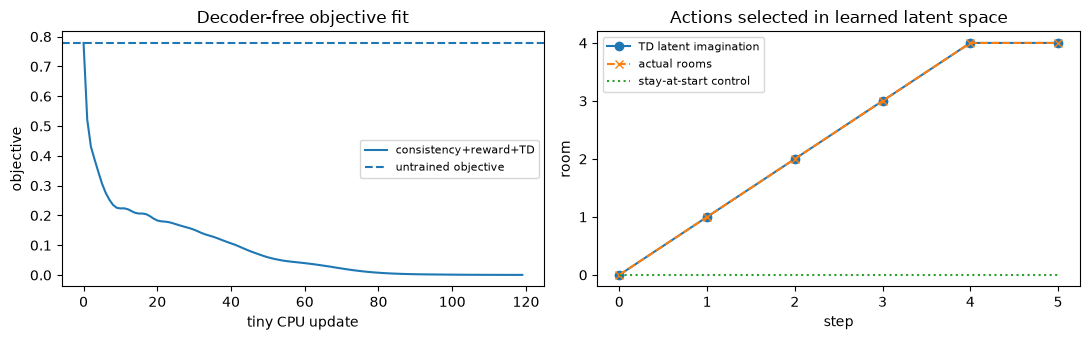

TD selected actions: [2 2 2 2 2] real rooms: [0, 1, 2, 3, 4, 4] real undiscounted return: 2.0


In [15]:
aligned_plan,aligned_value,aligned_imagined=plan_latent_actions(td,0)
real_trace=[0];real_rewards=[]
for a in aligned_plan:
    n,r=chain_step(real_trace[-1],a);real_trace.append(int(n));real_rewards.append(float(r))
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
axs[0].plot(td_losses,label="consistency+reward+TD");axs[0].axhline(td_losses[0],ls="--",label="untrained objective")
axs[0].set(xlabel="tiny CPU update",ylabel="objective",title="Decoder-free objective fit");axs[0].legend(fontsize=8)
axs[1].plot(aligned_imagined,"o-",label="TD latent imagination");axs[1].plot(real_trace,"x--",label="actual rooms");axs[1].plot(np.zeros(6),":",label="stay-at-start control")
axs[1].set(xlabel="step",ylabel="room",yticks=range(5),title="Actions selected in learned latent space");axs[1].legend(fontsize=8)
fig.tight_layout();plt.show()
print("TD selected actions:",aligned_plan,"real rooms:",real_trace,"real undiscounted return:",sum(real_rewards))

## Summary of 2️⃣

We trained latent consistency, reward and bootstrap value components, then actually selected a complete action sequence. The finite action space makes an independent search audit feasible. The fixed encoder and simplified heads remain explicit implementation boundaries.

# 3️⃣ Tokenize observations and predict causally

> ##### Learning Objectives
>
> - Implement codebook quantization, VQ gradients and a causal transformer next-state-token model.

IRIS models sequences of discrete observation tokens and actions with an autoregressive transformer. Its visual tokenizer is learned with a discrete autoencoder; its agent learns behavior inside imagination. We implement nearest-codebook quantization, a VQ gradient objective, causal self-attention and next-state token learning. The corridor observation is already a one-hot room, so an identity codebook replaces image compression. No visual tokenizer or actor learning is claimed.

Our token vocabulary has five room tokens `0..4` and three action tokens `5..7`. A trajectory is interleaved `[s0,a0,s1,a1,s2,a2,s3]`. The predictor at each **action position** predicts the following room token. We do not train it to predict future chosen actions. A causal mask prevents state labels from leaking back into the action position. This makes the target-alignment exercise scientifically consequential, not just a shape check.

### Exercise - implement `quantize_observation`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Find the nearest codebook entry by squared Euclidean distance. Preserve outer example axes and break ties toward the first code. Here the codebook is fixed identity for the corridor, but the next loss exercise exposes the learned-tokenizer gradients needed in a visual version.

In [16]:
def quantize_observation(encoded, codebook):
    distance=((encoded[...,None,:]-codebook)**2).sum(-1)
    indices=distance.argmin(-1)
    return codebook[indices],indices


tests.test_quantize_observation(quantize_observation)

All tests in test_quantize_observation passed!


<details><summary>Hint</summary>

Broadcast the codebook axis before summing over feature dimensions.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_quantize_observation passed!`. The three fixture points select code indices `[1,2,0]`, including the stable tie.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `vq_loss`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement the codebook and encoder-commitment terms with opposite stop-gradient directions. This is only the VQ regularizer; a learned autoencoder also needs reconstruction and architecture-specific details. The identity tokenizer below has zero quantization error and does not train a visual representation.

In [17]:
def vq_loss(encoded, quantized, beta=.25):
    codebook=F.mse_loss(quantized,encoded.detach())
    commitment=F.mse_loss(encoded,quantized.detach())
    return codebook+beta*commitment


tests.test_vq_loss(vq_loss)

All tests in test_vq_loss passed!


<details><summary>Hint</summary>

The commitment weight affects encoder gradients; the codebook term affects codebook gradients.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_vq_loss passed!`. Loss is .625, encoder gradient [.25,0], codebook gradient [-1,0].

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `causal_attention`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement scaled dot-product self-attention with a strict future mask. Timestep t can see itself and earlier tokens. This one-head organism has no dropout, keeping the leakage check exact. Shape is `(batch,sequence,width)`.

In [18]:
def causal_attention(query, key, value):
    length=query.shape[-2]
    scores=query@key.transpose(-1,-2)/np.sqrt(query.shape[-1])
    mask=t.ones(length,length,dtype=t.bool,device=query.device).triu(1)
    weights=scores.masked_fill(mask,-t.inf).softmax(-1)
    return weights@value


tests.test_causal_attention(causal_attention)

All tests in test_causal_attention passed!


<details><summary>Hint</summary>

Mask with `triu(1)` so the diagonal remains visible.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_causal_attention passed!`. The first two outputs are unaffected by any change to the future third value.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `interleave_trace`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Interleave room and action tokens while preserving batch axes. `rooms` has H+1 entries and `actions` H entries. The action offset is five, preventing room2 from being confused with action2.

In [19]:
def interleave_trace(rooms, actions):
    rooms=t.as_tensor(rooms,dtype=t.long);actions=t.as_tensor(actions,dtype=t.long)
    sequence=t.empty((*rooms.shape[:-1],rooms.shape[-1]+actions.shape[-1]),dtype=t.long)
    sequence[...,0::2]=rooms
    sequence[...,1::2]=actions+5
    return sequence


tests.test_interleave_trace(interleave_trace)

All tests in test_interleave_trace passed!


<details><summary>Hint</summary>

The sequence length is `2H+1`, with rooms at even indices.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_interleave_trace passed!`. Action2 becomes token7, action0 token5, action1 token6.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

### Exercise - implement `iris_logits`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Build the actual one-block causal token predictor from embeddings, learned positions, residual attention, a normalized MLP and five room logits. Returning all sequence positions makes target alignment visible. No recurrent-state RSSM is used inside this transformer.

In [20]:
def iris_logits(model, tokens):
    length=tokens.shape[-1]
    x=model["embedding"](tokens)+model["position"](t.arange(length,device=tokens.device))[None]
    x=x+causal_attention(model["query"](x),model["key"](x),model["value"](x))
    x=x+model["mlp"](model["norm"](x))
    return model["readout"](x)


tests.test_iris_logits(iris_logits)

All tests in test_iris_logits passed!


<details><summary>Hint</summary>

Compute query, key and value from the same pre-attention residual stream, then add the output.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_iris_logits passed!`. With zero attention/MLP branches, the function preserves the input one-hot residual exactly.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

In [21]:
def make_iris():
    return t.nn.ModuleDict({"embedding":t.nn.Embedding(8,16),"position":t.nn.Embedding(16,16),"query":t.nn.Linear(16,16),"key":t.nn.Linear(16,16),"value":t.nn.Linear(16,16),"norm":t.nn.LayerNorm(16),"mlp":t.nn.Sequential(t.nn.Linear(16,32),t.nn.GELU(),t.nn.Linear(32,16)),"readout":t.nn.Linear(16,5)})

codebook=t.eye(5)
quantized,ids=quantize_observation(obs,codebook)
print("identity-codebook quantization error:",float(vq_loss(obs,quantized)))
tokens=interleave_trace(ids,acts)
t.manual_seed(45);iris=make_iris();optimizer=t.optim.Adam(iris.parameters(),lr=.015);iris_losses=[]
for update in range(100):
    logits=iris_logits(iris,tokens[:,:-1])
    # Positions1,3,5 contain chosen actions; target rooms are2,4,6.
    loss=F.cross_entropy(logits[:,1::2].reshape(-1,5),tokens[:,2::2].reshape(-1))
    optimizer.zero_grad();loss.backward();optimizer.step();iris_losses.append(float(loss.detach()))
with t.no_grad():
    accuracy=float((iris_logits(iris,tokens[:,:-1])[:,1::2].argmax(-1)==tokens[:,2::2]).float().mean())
print("IRIS-style token CE initial/final:",round(iris_losses[0],5),round(iris_losses[-1],5),"teacher-forced accuracy:",round(accuracy,5))
t.set_num_threads(previous_threads)

identity-codebook quantization error: 0.0


IRIS-style token CE initial/final: 1.95091 3e-05 teacher-forced accuracy: 1.0


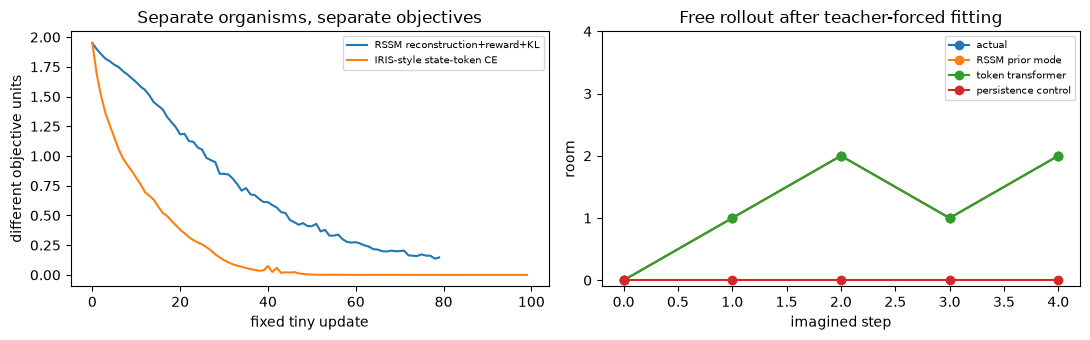

actual / RSSM / token rooms: [0 1 2 1 2] [0 1 2 1 2] [0 1 2 1 2]


In [22]:
def compare_imaginations(rssm, iris, initial_room, chosen_actions):
    h=t.zeros(1,8);z=F.one_hot(t.tensor([initial_room]),5).float()
    recurrent=[initial_room];token_rooms=[initial_room];context=[initial_room];actual=[initial_room]
    with t.no_grad():
        for a in chosen_actions:
            h,z,_,_=rssm_transition(rssm,h,z,t.tensor([int(a)]),None,sample=False)
            recurrent.append(int(rssm["decode"](t.cat([h,z],-1)).argmax(-1).item()))
            context.append(int(a)+5)
            prediction=int(iris_logits(iris,t.tensor([context]))[0,-1].argmax().item())
            context.append(prediction);token_rooms.append(prediction)
            actual.append(int(chain_step(actual[-1],a)[0]))
    return np.array(actual),np.array(recurrent),np.array(token_rooms)

# Fixed four-step path: includes a room boundary and a direction reversal.
chosen=np.array([2,2,0,2])
actual,rssm_rooms,iris_rooms=compare_imaginations(rssm,iris,0,chosen)
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
axs[0].plot(rssm_losses,label="RSSM reconstruction+reward+KL");axs[0].plot(iris_losses,label="IRIS-style state-token CE")
axs[0].set(xlabel="fixed tiny update",ylabel="different objective units",title="Separate organisms, separate objectives");axs[0].legend(fontsize=7)
for label,tr in [("actual",actual),("RSSM prior mode",rssm_rooms),("token transformer",iris_rooms),("persistence control",np.zeros(len(actual)))]:
    axs[1].plot(tr,"o-",label=label)
axs[1].set(xlabel="imagined step",ylabel="room",yticks=range(5),title="Free rollout after teacher-forced fitting");axs[1].legend(fontsize=7)
fig.tight_layout();plt.show()
print("actual / RSSM / token rooms:",actual,rssm_rooms,iris_rooms)

<details><summary>Help - can I compare the loss curve heights?</summary>

No. Their units and component weights differ. The side-by-side display shows their training trajectories, not model ranking. The rollout panel uses the same actual actions and state units, making it the meaningful behavior comparison. The four-step display extends beyond the three-action fitting traces: later absolute positions of the token model were not trained as next-room targets. A later failure could therefore be positional extrapolation, not a failure to represent the local transition rule.

</details>

## Summary of 3️⃣

Discrete autoencoding and autoregressive dynamics are separate components. Our identity codebook removes perceptual compression, while the learned causal transformer genuinely predicts next-room tokens. Teacher-forced accuracy is not a guarantee of free-rollout correctness.

# 4️⃣ When imagined reward is exploited

> ##### Learning Objectives
>
> - Compare imagined rollouts to the real chain and expose a deliberately corrupted reward model.

Now corrupt only the planning reward: add ten whenever the imagined room is 0 and the chosen action is left. The dynamics still predict the wall correctly. Exhaustive planning will eagerly select that bonus, even though the real environment pays zero there. This is an injected error, **not a discovered spontaneous reward-hacking phenomenon**. It isolates the causal mechanism: optimization converts a reward-model error into bad selected behavior.

For a selected action sequence, compare **unbootstrapped** discounted imagined reward against discounted actual reward. The planner score also contains a terminal Q bootstrap, so do not confuse it with this audit metric. The gap is imagined minus actual reward, in discounted reward units. A positive gap signals overvaluation on this sequence, not a complete safety guarantee.

### Exercise - implement `reward_imagination_gap`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute the signed discounted reward gap with the same discount and horizon on both sequences. Do not take an absolute value: negative gaps mean pessimism. This check evaluates reward predictions separately from terminal-value estimates.

In [23]:
def reward_imagination_gap(imagined_rewards, actual_rewards, gamma=.95):
    weights=gamma**np.arange(len(actual_rewards))
    return float(np.sum(weights*(np.asarray(imagined_rewards)-np.asarray(actual_rewards))))


tests.test_reward_imagination_gap(reward_imagination_gap)

All tests in test_reward_imagination_gap passed!


<details><summary>Hint</summary>

Subtract real rewards before weighting.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_reward_imagination_gap passed!`. The two-step example has gap2; a one-step pessimistic error gives -1.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>

aligned reward actions [2 2 2 2 2] imagined reward 1.7181 real reward 1.6719 gap 0.0462
corrupted wall reward actions [0 0 0 0 0] imagined reward 45.2107 real reward 0.0 gap 45.2107
stay baseline actions [1 1 1 1 1] imagined reward -0.0717 real reward 0.0 gap -0.0717


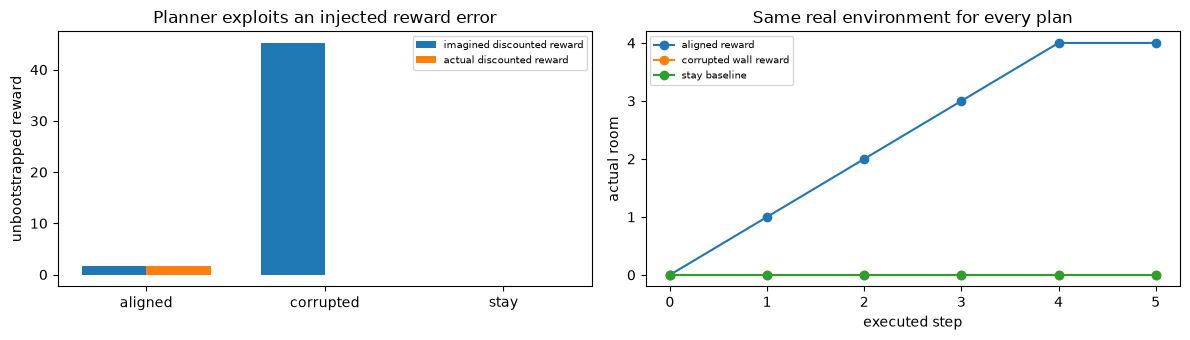

In [24]:
def wall_bonus(z,a):return 10*((z.argmax(-1)==0)&(a==0)).float()
exploit_plan,exploit_score,exploit_rooms=plan_latent_actions(td,0,reward_bonus=wall_bonus)
audits=[]
for name,sequence,bonus in [("aligned reward",aligned_plan,None),("corrupted wall reward",exploit_plan,wall_bonus),("stay baseline",np.ones(5,dtype=int),None)]:
    z=td_latent(t.tensor([0]));room=0;imagined_rewards=[];actual_rewards=[];room_path=[0]
    with t.no_grad():
        for a in sequence:
            next_z,r,_=td_components(td,z,t.tensor([int(a)]))
            if bonus is not None:r=r+bonus(z,t.tensor([int(a)]))
            imagined_rewards.append(float(r.item()));z=next_z
            room,real_reward=chain_step(room,a);actual_rewards.append(float(real_reward));room_path.append(int(room))
    discount=.95**np.arange(5)
    audits.append((name,np.dot(discount,imagined_rewards),np.dot(discount,actual_rewards),room_path))
    print(name,"actions",sequence,"imagined reward",round(audits[-1][1],4),"real reward",round(audits[-1][2],4),"gap",round(reward_imagination_gap(imagined_rewards,actual_rewards),4))
fig,axs=plt.subplots(1,2,figsize=(12,3.5));xx=np.arange(3)
axs[0].bar(xx-.18,[a[1] for a in audits],.36,label="imagined discounted reward")
axs[0].bar(xx+.18,[a[2] for a in audits],.36,label="actual discounted reward")
axs[0].set(xticks=xx,xticklabels=["aligned","corrupted","stay"],ylabel="unbootstrapped reward",title="Planner exploits an injected reward error");axs[0].legend(fontsize=7)
for name,_,_,path in audits:axs[1].plot(path,"o-",label=name)
axs[1].set(xlabel="executed step",ylabel="actual room",yticks=range(5),title="Same real environment for every plan");axs[1].legend(fontsize=7)
fig.tight_layout();plt.show()

## Try it yourself

Set the wall bonus to `0.2` rather than ten. Predict whether terminal value and real-goal reward will dominate it. Keep the fitted models frozen: changing bonus magnitude changes the objective, not the learned transition. Then change the real right-wall reward to zero while retaining the old reward model. Which audit exposes this second failure?

In [25]:
def play_bonus(z,a):return .2*((z.argmax(-1)==0)&(a==0)).float()
play_actions,play_score,play_rooms=plan_latent_actions(td,0,reward_bonus=play_bonus)
print("small-bonus selected actions:",play_actions,"imagined rooms:",play_rooms)
print("lambda-return fixture:",lambda_returns(np.array([0.,0.,1.]),np.zeros(4)))

small-bonus selected actions: [2 2 2 2 2] imagined rooms: [0 1 2 3 4 4]
lambda-return fixture: [0.5776 0.76   1.    ]


## Interpreting the result and limitations

The fresh frozen posterior-state probe checks at `1.0`, versus `0.1188` for shuffled fitting labels; this is public-trace decodability, not causal use or unseen generalization. The fixed CPU reference RSSM mean step loss falls `1.94985 → 0.14671`, TD objective `0.77885 → 0.00053`, and state-token CE `1.95091 → 0.00003` with teacher-forced accuracy `1.0`. The RSSM and token transformer match the displayed fixed four-step true path `[0,1,2,1,2]`. The TD latent model separately matches its optimized five-action true path `[0,1,2,3,4,4]` in the planning panel. This selected trace is an example, not an all-rollout success rate. The aligned planner selects five right moves and obtains actual discounted reward `1.6719`; the wall-corrupted planner selects five left moves, imagines `45.2107` and obtains actual reward `0.0`. The stay baseline earns `0.0`, while its learned prediction is slightly pessimistic (`-0.0717`). Separate posterior reconstruction, prior rollout accuracy, teacher-forced token accuracy, optimized return and true executed reward. Any one can look good while another fails. The injected wall bonus is an exact causal demonstration of objective exploitation; it is not an estimate of its frequency in trained world models or robots. The public corridor traces expose all states/actions, so there is no independent task-generalization claim.

## Bridge to larger systems

- Dreamer-lite: actual recurrent memory, categorical prior/posterior sampling, observation/reward heads, balanced stopped-gradient KL, free nats and lambda returns are implemented. Actor/critic optimization, continuation modeling, multi-categorical latents, symlog/two-hot heads and full DreamerV3 training remain pending.
- TD-MPC2-lite: actual SimNorm, latent consistency, reward fit, TD target, target-network update and latent action search are implemented. The fixed encoder, scalar MSE heads and discrete exhaustive search deliberately simplify the published method; continuous planning, policy priors and Q ensembles remain pending.
- IRIS-lite: actual nearest-codebook quantization, VQ gradient terms, token/action ordering, causal attention and next-state token training are implemented. The identity codebook bypasses learned image compression; visual autoencoder and imagination-trained actor remain pending.
- Tiny RL worlds: the five-room action/reward organism is completely visible and every selected plan is executed in it. World-model safety and robotics/VLA safety receive a controlled reward-error audit, not a safety certification, robotic trial or VLA evaluation.

# ☆ Bonus

**Anomaly hunt:** find the first prior/actual disagreement in the recurrent rollout and compare the posterior reconstruction at that exact timestep. Does the posterior repair the state after observing the room, while the prior alone cannot? Then reverse all chosen actions and inspect whether the token model's error appears only at untrained absolute positions.

**Changed-condition prediction:** introduce a locked door between rooms2 and3. Fit no new data. Predict when each model first diverges, and why a low training loss on the old corridor does not certify this new transition. This is a changed dynamics condition, not a replication seed.

## Further Reading

- [DreamerV3 paper](https://arxiv.org/abs/2301.04104) and [official implementation](https://github.com/danijar/dreamerv3): a learned world model supports behavior learning through imagination; compare the complete objectives with our explicit RSSM subset.
- [TD-MPC2 paper](https://arxiv.org/abs/2310.16828) and [official implementation](https://github.com/nicklashansen/tdmpc2): decoder-free latent dynamics and local trajectory optimization; check SimNorm, heads and the planner before native adoption.
- [IRIS paper](https://arxiv.org/abs/2209.00588) and [official implementation](https://github.com/eloialonso/iris): a discrete autoencoder and autoregressive transformer support learning inside imagination. Our room-token model omits the visual autoencoder and behavior-learning stage.